# 04．Tag 充電 Trace：從 RF 到儲能變化

**狀態：可執行的教學原型；尚待人工逐段接受，核心先保留在本 Notebook。**

本單元把已確認的充電與狀態設計轉為可以逐 cell 執行、改值及核對的 trace。
閱讀順序是「設定 → 單程 RF → RF/DC 轉換 → 四種電量邊界 → 耗盡分段 → 曲線 → 檢查」。

- 這裡驗證充電、背景恢復與手動選定操作的狀態／能量紀錄，尚未實作完整 Tag 狀態引擎的環境接線或 Baseline。
- 初始電量仍為 1 μJ；0.8 μJ 是運行途中經過先前耗能後的快照。
- 所有功率先用 W、電量用 J、外部時間用整數 ns；表格與圖才換成 μW、μJ、ms。
- 數值是已接受的研究基準，不是完整硬體的量測或擬合結果。

來源：[組態與實作範圍](../ReferDoc/Plan/Tag_Energy_Implementation_Readiness.md)、[已接受能量組態](../ReferDoc/Plan/EN02_Tag_Energy_Profile_Candidate.md)、[中文設計 Trace](../docs/architecture/tag-energy-trace/README.zh-TW.md)。


## 1．載入計算與展示工具

標準函式庫 `math` 提供穩定的指數運算；Matplotlib 與 IPython 沿用既有 Notebook 環境。
本單元不抽亂數、不修改既有拓撲，也不從通道模組取得去回程功率。

來源：[既有資源 Notebook](03_resource_timeline.ipynb)、[程式／設計狀態對照](../docs/architecture/tag-energy-trace/code-trace.md)。


In [1]:
import math


### 1.1．展示與工作目錄

下列工具沿用現有 Notebook；工作目錄可為專案根目錄或 notebooks。表格直接顯示，不另寫出檔案。


In [2]:
from pathlib import Path
import json
from io import BytesIO

import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'ReferDoc/Plan').is_dir():
    ROOT = ROOT.parent

if not (ROOT / 'ReferDoc/Plan').is_dir():
    raise ValueError('Run from the project root or notebooks directory')


def show_table(rows):
    headers = tuple(rows[0])
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join('---' for _ in headers) + ' |']
    for row in rows:
        lines.append('| ' + ' | '.join(str(row[header]) for header in headers) + ' |')
    display(Markdown('\n'.join(lines)))


## 2．集中列出已接受設定

容量、初始電量與功耗都使用 SI 單位。接收／D2R 功耗及啟動成本列在表中作為介面背景，這份充電 trace 不執行那些操作。
正常待機為 10 nW；只有已進入被動恢復狀態時，才使用零額外恢復功耗。
若變更研究參數，末段固定對照值可能失敗；那表示需要新的參考案例，不能用新程式重新產生舊預期值。

來源：[R-01 §81、§82、§88](../ReferDoc/Plan/R-01_System_Model_and_Baseline_Decision_Record.md)、[能量基準](../ReferDoc/Plan/EN02_Tag_Energy_Profile_Candidate.md)。


In [3]:
energy_settings = {
    'capacity_j': 1e-6,
    'initial_energy_j': 1e-6,
    'quiescent_power_w': 10e-9,
    'receive_power_w': 1e-6,
    'd2r_power_w': 1e-6,
    'activation_energy_j': 1e-9,
    'maximum_dc_w': 10e-6,
    'slope_per_w': 2e5,
    'midpoint_w': 10e-6,
}
ue_power_dbm = 20.0
ul_gain_db = -50.0
interval_ns = 400_000_000
snapshot_energy_j = 0.8e-6


### 2.1．核對設定表

先顯示每個具名參數的 SI 數值，再往下追蹤計算。


In [4]:
settings_rows = []
for name, value in energy_settings.items():
    settings_rows.append({'設定名稱': name, 'SI 數值': f'{value:.12g}'}) # .12g -> genral formate , The floor only capacity 12 number
show_table(settings_rows)


| 設定名稱 | SI 數值 |
| --- | --- |
| capacity_j | 1e-06 |
| initial_energy_j | 1e-06 |
| quiescent_power_w | 1e-08 |
| receive_power_w | 1e-06 |
| d2r_power_w | 1e-06 |
| activation_energy_j | 1e-09 |
| maximum_dc_w | 1e-05 |
| slope_per_w | 200000 |
| midpoint_w | 1e-05 |

## 3．從單程 RF 輸入開始

UL 使用所屬 UE 的固定 20 dBm 發射功率，乘上既定 −50 dB 功率增益。
DL 則使用所屬 DU 當窗功率乘上單程 `g0 / distance_m**2`，距離維持已確認的 1～50 m。

既有 `channel.link_budget()` 算的是 Reader 收到的去回程反射功率，包含反射損耗及兩次單程增益，不能直接當作採能輸入。
既有 `current_resource()` 也沒有 UL／DL 方向及來源功率；正式接入時需由環境提供當下資訊。
本 cell 明列輸入，不假裝已完成該環境介面。

來源：[單程來源組態](../ReferDoc/Plan/EN01_Source_RF_Profile_Candidate.md)、[既有去回程計算](../src/channel/channel_model.py)、[時序投影](../src/timeline/resource_timeline.py)。


In [5]:
ue_power_w = 10 ** ((ue_power_dbm - 30) / 10)
ul_gain_linear = 10 ** (ul_gain_db / 10)
rf_input_w = ue_power_w * ul_gain_linear

show_table([
    {'步驟': 'UE 發射功率', '數值': f'{ue_power_w:.9g}', '單位': 'W'},
    {'步驟': '單程功率增益', '數值': f'{ul_gain_linear:.9g}', '單位': '無單位'},
    {'步驟': 'Tag 收到的 RF', '數值': f'{rf_input_w * 1e6:.9g}', '單位': 'μW'},
])


| 步驟 | 數值 | 單位 |
| --- | --- | --- |
| UE 發射功率 | 0.1 | W |
| 單程功率增益 | 1e-05 | 無單位 |
| Tag 收到的 RF | 1 | μW |

## 4．把 RF 功率轉為 DC 功率

沿用已接受的零輸入校正 Sigmoid：

$$\Omega=\frac{1}{1+e^{sz}},\qquad
L(P)=\frac{M}{1+e^{-s(P-z)}},\qquad
F(P)=\frac{L(P)-M\Omega}{1-\Omega}.$$

程式使用等價的 `expm1` 表示式，避免很弱輸入時兩個接近值相減。
輸入不得為負、NaN、無限大或 bool；參數必須為正且可數值表示。
另要求全域斜率上界 $Ms/[4(1-\Omega)]\le1$；這是本基準保證被動性的充分條件，不是通用硬體擬合器。
因此 $F(0)=0$ 且 $0\le F(P)\le P$，不靠裁切輸出來隱藏不合適的係數。

來源：[原文與零輸入校正對照](../ReferDoc/Plan/WCSP2025_Charging_Model_Mapping.md)、[接受的合成係數](../ReferDoc/Plan/EN02_Tag_Energy_Profile_Candidate.md)。


In [6]:
def harvested_power_w(rf_input_w, *, maximum_w, slope_per_w, midpoint_w):
    values = {
        'rf_input_w': rf_input_w,
        'maximum_w': maximum_w,
        'slope_per_w': slope_per_w,
        'midpoint_w': midpoint_w,
    }
    for name, value in values.items():
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError(f'{name} must be a finite number')

        try:
            finite = math.isfinite(value)
        except OverflowError:
            finite = False

        if not finite:
            raise ValueError(f'{name} must be a finite number')

    if rf_input_w < 0:
        raise ValueError('rf_input_w must be non-negative')

    if maximum_w <= 0 or slope_per_w <= 0 or midpoint_w <= 0:
        raise ValueError('Sigmoid parameters must be positive')

    rf_input_w = float(rf_input_w)
    maximum_w = float(maximum_w)
    slope_per_w = float(slope_per_w)
    midpoint_w = float(midpoint_w)

    shape = slope_per_w * midpoint_w
    if not math.isfinite(shape):
        raise ValueError('Sigmoid shape must be finite')

    inverse_shape_exp = math.exp(-shape)
    omega = inverse_shape_exp / (1 + inverse_shape_exp)
    if omega == 0:
        raise ValueError('Sigmoid shape is outside the supported numerical range')

    slope_bound = maximum_w * slope_per_w / (4 * (1 - omega))
    if not math.isfinite(slope_bound) or slope_bound > 1:
        raise ValueError('Sigmoid parameters must satisfy the passive slope bound')

    scaled_input = slope_per_w * rf_input_w
    exponential = math.exp(-scaled_input)
    normalized_fraction = omega * (-math.expm1(-scaled_input)) / (omega + (1 - omega) * exponential)
    return maximum_w * normalized_fraction


### 4.1．核對 DC 數值

呼叫上方的轉換函式，顯示 RF 與 DC 功率；本例只做一次轉換，不抽樣封包結果。


In [7]:
dc_power_w = harvested_power_w(
    rf_input_w,
    maximum_w=energy_settings['maximum_dc_w'],
    slope_per_w=energy_settings['slope_per_w'],
    midpoint_w=energy_settings['midpoint_w'],
)
show_table([
    {'物理量': 'RF 輸入', '功率 μW': f'{rf_input_w * 1e6:.12f}'},
    {'物理量': 'DC 輸出', '功率 μW': f'{dc_power_w * 1e6:.12f}'},
])


| 物理量 | 功率 μW |
| --- | --- |
| RF 輸入 | 1.000000000000 |
| DC 輸出 | 0.257132357096 |

## 5．只對允許的階段計入採能

$H=1$ 只代表 UE 通訊前綴中的 UL 或 DL；其他階段為零。
下表假設有相同的 1 μW RF 可供比較，示範相位門檻的效果；並非聲稱空檔實際存在該發射源。
表內只列採能輸出，不把 Paging／D2R 的實際操作耗電當作待機成本。

來源：[採能時段與恢復規則](../ReferDoc/Plan/EN02_Tag_Energy_Profile_Candidate.md)。


In [8]:
phase_gates = (
    ('UE UL', 1), ('UE DL', 1), ('RF switch', 0),
    ('Paging', 0), ('D2R', 0), ('Guard', 0), ('Inter-window gap', 0),
)
phase_rows = []
for phase_name, harvesting_allowed in phase_gates:
    phase_rows.append({
        '階段': phase_name,
        'H': harvesting_allowed,
        '允許的 DC 功率 μW': f'{harvesting_allowed * dc_power_w * 1e6:.12f}',
    })
show_table(phase_rows)


| 階段 | H | 允許的 DC 功率 μW |
| --- | --- | --- |
| UE UL | 1 | 0.257132357096 |
| UE DL | 1 | 0.257132357096 |
| RF switch | 0 | 0.000000000000 |
| Paging | 0 | 0.000000000000 |
| D2R | 0 | 0.000000000000 |
| Guard | 0 | 0.000000000000 |
| Inter-window gap | 0 | 0.000000000000 |

## 6．正常待機中的一次充電

持續時間先由整數 ns 轉為秒。RF 經轉換後的 DC 才能積成電量。
這段沒有操作啟動事件，因此不扣 1 nJ；它也不授予未來操作的電量信用。

$$E_{next}=E+F(P_{RF})\Delta t-P_q\Delta t.$$

預期從 0.8 μJ 增加至約 0.89885294284 μJ；容量上限在下一節處理。

來源：[已核對數值](../docs/architecture/tag-energy-trace/worked-example.json)。


In [9]:
duration_s = interval_ns / 1_000_000_000
harvested_energy_j = dc_power_w * duration_s
quiescent_energy_j = energy_settings['quiescent_power_w'] * duration_s
normal_after_j = snapshot_energy_j + harvested_energy_j - quiescent_energy_j

show_table([
    {'項目': '起始快照', '電量 μJ': f'{snapshot_energy_j * 1e6:.12f}'},
    {'項目': '採得能量', '電量 μJ': f'{harvested_energy_j * 1e6:.12f}'},
    {'項目': '待機消耗', '電量 μJ': f'{quiescent_energy_j * 1e6:.12f}'},
    {'項目': '更新後電量', '電量 μJ': f'{normal_after_j * 1e6:.12f}'},
])


| 項目 | 電量 μJ |
| --- | --- |
| 起始快照 | 0.800000000000 |
| 採得能量 | 0.102852942838 |
| 待機消耗 | 0.004000000000 |
| 更新後電量 | 0.898852942838 |

## 7．容量飽和、被動恢復與無採能空檔

四列是互相獨立的 400-ms 案例，不是完整服務執行的連續時間軸。
容量飽和後的多餘能量丟棄；被動恢復不另扣待機成本；正常空檔仍耗電。
本節範例都不會在區段中途耗盡，所以可直接核對收支。耗盡另外在下一節分段。

來源：[已接受能量案例](../docs/architecture/tag-energy-trace/README.zh-TW.md)。


In [10]:
capacity_j = energy_settings['capacity_j']
saturated_before_j = 0.95e-6
saturated_raw_j = saturated_before_j + harvested_energy_j - quiescent_energy_j
saturated_after_j = min(capacity_j, saturated_raw_j)
spilled_energy_j = saturated_raw_j - saturated_after_j
recovery_after_j = harvested_energy_j
gap_after_j = snapshot_energy_j - quiescent_energy_j

case_results = [
    {'case': 'normal_charge', 'before_j': snapshot_energy_j, 'harvested_j': harvested_energy_j, 'consumed_j': quiescent_energy_j, 'spilled_j': 0.0, 'after_j': normal_after_j},
    {'case': 'capacity_saturation', 'before_j': saturated_before_j, 'harvested_j': harvested_energy_j, 'consumed_j': quiescent_energy_j, 'spilled_j': spilled_energy_j, 'after_j': saturated_after_j},
    {'case': 'passive_recovery', 'before_j': 0.0, 'harvested_j': harvested_energy_j, 'consumed_j': 0.0, 'spilled_j': 0.0, 'after_j': recovery_after_j},
    {'case': 'inter_window_gap', 'before_j': snapshot_energy_j, 'harvested_j': 0.0, 'consumed_j': quiescent_energy_j, 'spilled_j': 0.0, 'after_j': gap_after_j},
]
case_rows = []
for result in case_results:
    row = {'案例': result['case']}
    for field in ('before_j', 'harvested_j', 'consumed_j', 'spilled_j', 'after_j'):
        row[field.replace('_j', '_μJ')] = f'{result[field] * 1e6:.12f}'
    case_rows.append(row)
show_table(case_rows)


| 案例 | before_μJ | harvested_μJ | consumed_μJ | spilled_μJ | after_μJ |
| --- | --- | --- | --- | --- | --- |
| normal_charge | 0.800000000000 | 0.102852942838 | 0.004000000000 | 0.000000000000 | 0.898852942838 |
| capacity_saturation | 0.950000000000 | 0.102852942838 | 0.004000000000 | 0.048852942838 | 1.000000000000 |
| passive_recovery | 0.000000000000 | 0.102852942838 | 0.000000000000 | 0.000000000000 | 0.102852942838 |
| inter_window_gap | 0.800000000000 | 0.000000000000 | 0.004000000000 | 0.000000000000 | 0.796000000000 |

## 8．電量在空檔中途耗盡時，先切段再更新

例：正常待機只剩 0.002 μJ，空檔為 400 ms，沒有允許的採能來源。
10 nW 的待機功耗在 200 ms 用完儲能；剩下 200 ms 處於零額外耗電的恢復狀態。
不能持續扣正常待機，然後用 `max(0, E)` 隱藏欠缺的能量。
這裡的耗盡點剛好是整數 ns；一般非整數 ns 交界的 Engine 排程尚未在此實作。

來源：[被動恢復決策](../ReferDoc/Plan/EN02_Tag_Energy_Profile_Candidate.md)。


In [11]:
depletion_initial_j = 0.002e-6
depletion_time_s = depletion_initial_j / energy_settings['quiescent_power_w']
normal_segment_ns = round(depletion_time_s * 1_000_000_000)
recovery_segment_ns = interval_ns - normal_segment_ns
normal_segment_consumed_j = energy_settings['quiescent_power_w'] * (normal_segment_ns / 1_000_000_000)
depleted_after_j = 0.0

show_table([
    {'區段': '正常待機直到耗盡', '時間 ns': normal_segment_ns, '消耗 μJ': f'{normal_segment_consumed_j * 1e6:.12f}'},
    {'區段': '被動恢復，空檔無採能', '時間 ns': recovery_segment_ns, '消耗 μJ': '0'},
])


| 區段 | 時間 ns | 消耗 μJ |
| --- | --- | --- |
| 正常待機直到耗盡 | 200000000 | 0.002000000000 |
| 被動恢復，空檔無採能 | 200000000 | 0 |

## 9．用曲線核對容量與耗盡交界

左圖比較三種充電案例及正常無採能空檔；右圖放大 0.002 μJ 的耗盡案例。
每條線是這份常功率手算例的解析曲線，不是 DES 模擬器輸出。
圖使用英文座標與 SI 衍生單位，避免依賴額外中文字型。

來源：第 6～8 節已列出的計算。


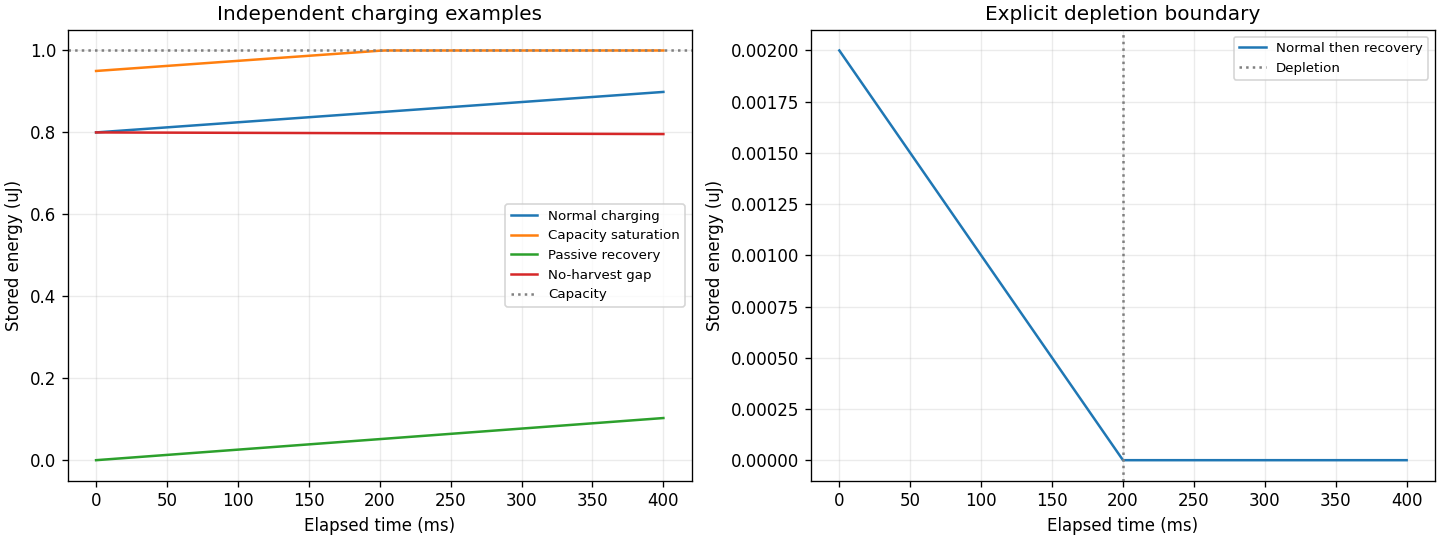

In [12]:
sample_times_s = [index * duration_s / 100 for index in range(101)]
normal_curve_uj = []
saturated_curve_uj = []
recovery_curve_uj = []
gap_curve_uj = []
depletion_curve_uj = []

for elapsed_s in sample_times_s:
    normal_energy_j = snapshot_energy_j + (dc_power_w - energy_settings['quiescent_power_w']) * elapsed_s
    near_capacity_j = saturated_before_j + (dc_power_w - energy_settings['quiescent_power_w']) * elapsed_s
    normal_curve_uj.append(min(capacity_j, normal_energy_j) * 1e6)
    saturated_curve_uj.append(min(capacity_j, near_capacity_j) * 1e6)
    recovery_curve_uj.append(min(capacity_j, dc_power_w * elapsed_s) * 1e6)
    gap_curve_uj.append((snapshot_energy_j - energy_settings['quiescent_power_w'] * elapsed_s) * 1e6)
    if elapsed_s < depletion_time_s:
        depletion_energy_j = depletion_initial_j - energy_settings['quiescent_power_w'] * elapsed_s
    else:
        depletion_energy_j = 0.0
    depletion_curve_uj.append(depletion_energy_j * 1e6)

sample_times_ms = [elapsed_s * 1000 for elapsed_s in sample_times_s]
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].plot(sample_times_ms, normal_curve_uj, label='Normal charging')
axes[0].plot(sample_times_ms, saturated_curve_uj, label='Capacity saturation')
axes[0].plot(sample_times_ms, recovery_curve_uj, label='Passive recovery')
axes[0].plot(sample_times_ms, gap_curve_uj, label='No-harvest gap')
axes[0].set(xlabel='Elapsed time (ms)', ylabel='Stored energy (uJ)', title='Independent charging examples')
axes[0].axhline(capacity_j * 1e6, color='grey', linestyle=':', label='Capacity')
axes[0].legend(fontsize=8)
axes[1].plot(sample_times_ms, depletion_curve_uj, label='Normal then recovery')
axes[1].axvline(depletion_time_s * 1000, color='grey', linestyle=':', label='Depletion')
axes[1].set(xlabel='Elapsed time (ms)', ylabel='Stored energy (uJ)', title='Explicit depletion boundary')
axes[1].legend(fontsize=8)

for axis in axes:
    axis.grid(alpha=0.25)
figure_buffer = BytesIO()
figure.savefig(figure_buffer, format='png', dpi=120)
display(Image(data=figure_buffer.getvalue()))
plt.close(figure)


## 10．核對獨立數值與能量收支

以下先用先前獨立 Decimal 計算保存的 JSON 作對照，再檢查 literal 預期值與每列能量守恆。
JSON 不由本 Notebook 重新產生。允許誤差只處理浮點表示，不是容量／耗盡裁切規則。
本節也確認正常待機與恢復的成本不同，且七個階段只有 UE UL／DL 允許採能。

來源：[獨立算術證據](../docs/architecture/tag-energy-trace/worked-example.json)、[公開邊界測試](../tests/energy/test_tag_energy_notebook.py)。


In [13]:
reference_path = ROOT / 'docs/architecture/tag-energy-trace/worked-example.json'
reference = json.loads(reference_path.read_text())
expected_dc_w = float(reference['dc_output_uw']) * 1e-6
assert math.isclose(dc_power_w, expected_dc_w, rel_tol=1e-12)
assert math.isclose(normal_after_j, 0.8988529428383909e-6, rel_tol=1e-12)
assert saturated_after_j == capacity_j
assert math.isclose(spilled_energy_j, 0.0488529428383909e-6, rel_tol=1e-12)
assert math.isclose(recovery_after_j, 0.10285294283839096e-6, rel_tol=1e-12)
assert math.isclose(gap_after_j, 0.796e-6, rel_tol=1e-12)
assert normal_segment_ns == 200_000_000
assert recovery_segment_ns == 200_000_000
assert math.isclose(normal_segment_consumed_j, depletion_initial_j, rel_tol=1e-12)
assert depleted_after_j == 0.0
assert [gate for _, gate in phase_gates] == [1, 1, 0, 0, 0, 0, 0]

for result, expected in zip(case_results, reference['examples'], strict=True):
    assert result['case'] == expected['case']
    expected_after_j = float(expected['final_energy_uj']) * 1e-6
    assert math.isclose(result['after_j'], expected_after_j, rel_tol=1e-12)
    balance_j = result['before_j'] + result['harvested_j'] - result['consumed_j'] - result['spilled_j']
    assert math.isclose(result['after_j'], balance_j, rel_tol=1e-12, abs_tol=1e-21)
    assert 0 <= result['after_j'] <= capacity_j

verification_summary = {
    'independent_cases': len(case_results),
    'depletion_boundary_ns': normal_segment_ns,
    'phase_gates': len(phase_gates),
    'status': 'PASS: scalar teaching trace only',
}
display(verification_summary)


{'independent_cases': 4,
 'depletion_boundary_ns': 200000000,
 'phase_gates': 7,
 'status': 'PASS: scalar teaching trace only'}

## 11．已確認的 Tag 狀態：先保留七種控制意義

狀態設計參考 PScatter，但保留我們的 DU／Reader、功耗及排程事件啟動假設。
`STATIC`／`SLEEP`／`WAIT_D2R` 都支付 10 nW；`PAGING_RX`／`BACKSCATTER` 支付 1 μW。
`WAKING` 是需要時扣一次 1 nJ 的零額外時長事件；`ENERGY_RECOVERY` 不另扣恢復電路功耗。

每個 Tag 使用不可變快照；函式回傳新的快照與紀錄，不修改輸入或其他 Tag。
區段收支以 Decimal 計算，外部時鐘仍是整數 ns。這是手動供給事件的狀態原型，不是完整 Engine。

來源：[已接受的狀態與轉移條件](../docs/architecture/tag-state-design.md)、[PScatter 對照與證據限制](../ReferDoc/Plan/PScatter_Tag_State_Mapping.md)。


In [14]:
from dataclasses import dataclass
from decimal import Decimal, localcontext
from enum import Enum


class TagMode(str, Enum):
    STATIC = 'STATIC'
    WAKING = 'WAKING'
    PAGING_RX = 'PAGING_RX'
    WAIT_D2R = 'WAIT_D2R'
    BACKSCATTER = 'BACKSCATTER'
    SLEEP = 'SLEEP'
    ENERGY_RECOVERY = 'ENERGY_RECOVERY'


@dataclass(frozen=True)
class TagSnapshot:
    tag_id: str
    now_ns: int
    energy_j: float
    mode: TagMode


@dataclass(frozen=True)
class TagTraceRow:
    start_ns: int
    end_ns: int
    mode: TagMode
    phase: str
    before_j: float
    harvested_j: float
    consumed_j: float
    spilled_j: float
    after_j: float
    note: str = ''


@dataclass(frozen=True)
class TagTrace:
    snapshot: TagSnapshot
    rows: tuple
    depletion_after_s: float | None = None
    receive_success: bool | None = None


D2R_OCCUPANCY_NS = {8: 35_000_000, 16: 63_000_000, 32: 118_000_000, 64: 228_000_000}
GUARD_NS = 200_000
INACTIVE_MODES = (TagMode.STATIC, TagMode.SLEEP, TagMode.ENERGY_RECOVERY)
RESOURCE_PHASES = ('UE_UL', 'UE_DL', 'RF_SWITCH', 'PAGING', 'WAIT_D2R', 'D2R', 'GUARD', 'GAP')


def _energy_decimal(value, name):
    if isinstance(value, bool) or not isinstance(value, (int, float)):
        raise ValueError(f'{name} must be a finite non-negative number')

    try:
        finite = math.isfinite(value)
    except OverflowError:
        finite = False

    if not finite or value < 0:
        raise ValueError(f'{name} must be a finite non-negative number')

    return Decimal(str(value))


def _nonnegative_ns(value, name):
    if type(value) is not int or value < 0:
        raise ValueError(f'{name} must be a non-negative integer ns value')

    return value


def _trace_settings(settings):
    if not isinstance(settings, dict):
        raise ValueError('settings must be the explicit energy settings dictionary')

    values = {}
    for name in ('capacity_j', 'quiescent_power_w', 'receive_power_w', 'd2r_power_w', 'activation_energy_j'):
        if name not in settings:
            raise ValueError(f'missing energy setting: {name}')
        values[name] = _energy_decimal(settings[name], name)

    if any(values[name] <= 0 for name in ('capacity_j', 'quiescent_power_w', 'receive_power_w', 'd2r_power_w')):
        raise ValueError('capacity and mode powers must be positive')

    return values


def _validate_snapshot(snapshot, values):
    if not isinstance(snapshot, TagSnapshot):
        raise ValueError('snapshot must be a TagSnapshot')

    if not isinstance(snapshot.tag_id, str) or not snapshot.tag_id.strip():
        raise ValueError('tag_id must be a non-empty string')

    _nonnegative_ns(snapshot.now_ns, 'now_ns')
    energy = _energy_decimal(snapshot.energy_j, 'energy_j')
    if energy > values['capacity_j']:
        raise ValueError('stored energy exceeds capacity')

    if not isinstance(snapshot.mode, TagMode):
        raise ValueError('mode must be TagMode')

    return energy


## 12．選定操作前，先檢查完整電量與時間

以下函式只執行呼叫者已選定的操作，不決定要服務哪個 Tag 或採用哪個 TBS。
先確認完整 Paging、等待、D2R、Guard 與啟動成本，再產生任何扣款紀錄。
非法／電量不足／時長不足的請求會直接拒絕，輸入快照維持原值。

D2R 必須嚴格早於服務期限；Guard 可依已選規則跨過評估終點，但整段仍須在外層 Window 內。
接收失敗也要支付完整實際傳輸成本。沒有新增 wake-up 封包、PSS 同步或功耗設定。
Paging 與等待時長由外部明列供給；函式不假裝已完成 CFA 回應時間表或完整資源驗證。


In [15]:
def trace_tag_operation(snapshot, *, tbs_bytes, paging_ns, wait_ns,
                        window_end_ns, deadline_ns, receive_success=True, cw_available=True, settings=None):
    # A caller supplies a selected operation; this function never chooses a Policy action.
    selected_settings = energy_settings if settings is None else settings
    values = _trace_settings(selected_settings)
    energy = _validate_snapshot(snapshot, values)
    if snapshot.mode not in INACTIVE_MODES:
        raise ValueError('a new operation requires an inactive Tag')

    if type(tbs_bytes) is not int or tbs_bytes not in D2R_OCCUPANCY_NS:
        raise ValueError('tbs_bytes must be one of 8, 16, 32, 64')

    _nonnegative_ns(paging_ns, 'paging_ns')
    _nonnegative_ns(wait_ns, 'wait_ns')
    _nonnegative_ns(window_end_ns, 'window_end_ns')
    _nonnegative_ns(deadline_ns, 'deadline_ns')
    if paging_ns == 0:
        raise ValueError('paging_ns must be positive')

    if type(receive_success) is not bool:
        raise ValueError('receive_success must be bool')

    if type(cw_available) is not bool or not cw_available:
        raise ValueError('CW must be available for the admitted D2R interval')

    d2r_ns = D2R_OCCUPANCY_NS[tbs_bytes]
    d2r_end_ns = snapshot.now_ns + paging_ns + wait_ns + d2r_ns
    guard_end_ns = d2r_end_ns + GUARD_NS
    if guard_end_ns > window_end_ns:
        raise ValueError('complete operation and Guard exceed the Window')

    if d2r_end_ns >= deadline_ns:
        raise ValueError('D2R completion must precede the exclusive deadline')

    with localcontext() as context:
        context.prec = 50
        segments = (
            (TagMode.WAKING, 'ACTIVATION', 0, Decimal(0), values['activation_energy_j']),
            (TagMode.PAGING_RX, 'PAGING', paging_ns, values['receive_power_w'], Decimal(0)),
            (TagMode.WAIT_D2R, 'WAIT_D2R', wait_ns, values['quiescent_power_w'], Decimal(0)),
            (TagMode.BACKSCATTER, 'D2R', d2r_ns, values['d2r_power_w'], Decimal(0)),
            (TagMode.SLEEP, 'GUARD', GUARD_NS, values['quiescent_power_w'], Decimal(0)),
        )
        required_energy = Decimal(0)
        for _, _, duration_ns, power_w, fixed_j in segments:
            required_energy += fixed_j + power_w * Decimal(duration_ns) / Decimal(1_000_000_000)

        if energy < required_energy:
            raise ValueError('stored energy does not cover the complete operation')

        rows = []
        cursor_ns = snapshot.now_ns
        for mode, phase, duration_ns, power_w, fixed_j in segments:
            before = energy
            consumed = fixed_j + power_w * Decimal(duration_ns) / Decimal(1_000_000_000)
            energy -= consumed
            note = ''
            if mode is TagMode.BACKSCATTER:
                note = 'receive success' if receive_success else 'receive failure; no energy refund'
            rows.append(TagTraceRow(cursor_ns, cursor_ns + duration_ns, mode, phase,
                                    _trace_float(before), 0.0, _trace_float(consumed), 0.0, _trace_float(energy), note))
            cursor_ns += duration_ns

        final_mode = TagMode.ENERGY_RECOVERY if energy == 0 else TagMode.SLEEP
        updated = TagSnapshot(snapshot.tag_id, cursor_ns, _trace_float(energy), final_mode)
    return TagTrace(updated, tuple(rows), receive_success=receive_success)


## 13．背景耗能與恢復：用狀態決定耗電，用階段決定採能

下列函式只處理 inactive 狀態；接收與反射必須經上一節完整操作檢查。
若正常背景耗能在區段中途到零，先解析求出耗盡位置，再用恢復成本計算剩餘區段。
耗盡 offset 以秒作診斷，不是送入 Engine 的浮點事件時間；對外 now_ns 仍保持整數。
恢復後即使已有正電量，也保持 ENERGY_RECOVERY，直到有效選擇通過 admission。


In [16]:
def _trace_float(value):
    result = float(value)
    if not math.isfinite(result) or (value != 0 and result == 0):
        raise ValueError('trace energy is outside the supported floating-point range')

    return result


def advance_tag_interval(snapshot, *, duration_ns, phase, rf_input_w=0.0, settings=None):
    # Only inactive accounting is public here; active intervals require complete admission.
    selected_settings = energy_settings if settings is None else settings
    values = _trace_settings(selected_settings)
    energy = _validate_snapshot(snapshot, values)
    if snapshot.mode not in INACTIVE_MODES:
        raise ValueError('background accounting requires an inactive Tag')

    _nonnegative_ns(duration_ns, 'duration_ns')
    if phase not in RESOURCE_PHASES:
        raise ValueError('unknown resource phase')

    for name in ('maximum_dc_w', 'slope_per_w', 'midpoint_w'):
        if name not in selected_settings:
            raise ValueError(f'missing conversion setting: {name}')

    dc = harvested_power_w(rf_input_w, maximum_w=selected_settings['maximum_dc_w'],
                           slope_per_w=selected_settings['slope_per_w'],
                           midpoint_w=selected_settings['midpoint_w'])
    allowed = phase in ('UE_UL', 'UE_DL')
    with localcontext() as context:
        context.prec = 50
        duration_s = Decimal(duration_ns) / Decimal(1_000_000_000)
        harvest_w = Decimal(str(dc)) if allowed else Decimal(0)
        harvested = harvest_w * duration_s
        recovering = snapshot.mode is TagMode.ENERGY_RECOVERY or energy == 0
        mode_power = Decimal(0) if recovering else values['quiescent_power_w']
        raw = energy + (harvest_w - mode_power) * duration_s
        depletion_s = None
        if not recovering and raw <= 0:
            depletion_s = energy / (mode_power - harvest_w)
            consumed = mode_power * depletion_s
            after = Decimal(0) if raw == 0 else harvest_w * (duration_s - depletion_s)
            recovering = True
        else:
            consumed = mode_power * duration_s
            after = raw

        spilled = max(Decimal(0), after - values['capacity_j'])
        after -= spilled
        final_mode = TagMode.ENERGY_RECOVERY if recovering else snapshot.mode
        end_ns = snapshot.now_ns + duration_ns
        row = TagTraceRow(snapshot.now_ns, end_ns, snapshot.mode, phase,
                          _trace_float(energy), _trace_float(harvested), _trace_float(consumed),
                          _trace_float(spilled), _trace_float(after),
                          'depletion split: offset is diagnostic seconds' if depletion_s is not None else '')
        updated = TagSnapshot(snapshot.tag_id, end_ns, _trace_float(after), final_mode)
    return TagTrace(updated, (row,), float(depletion_s) if depletion_s is not None else None)


## 14．把充電、切頻與選定操作接成一段可追蹤流程

run 初始快照使用 1 μJ。下例另接續先前的 0.8 μJ 運行中快照，時間從 1 s 起，不代表重設電池。
先 UL 採能 400 ms，再依既有組態切頻 1 ms，接著明列一筆 16-byte TBS 操作。

**示範時序輸入：** Paging 2 ms、等待 1 ms；這是 state trace 的外部輸入，不是新選定的 CFA response offset。
D2R 63 ms 與 Guard 200 μs 則沿用已接受組態；CW 可用是呼叫者提供的操作條件。
本次完整操作需要 0.066012 μJ，會在產生任何扣款前檢查。

來源：[狀態設計](../docs/architecture/tag-state-design.md)、[D2R 時長組態](../ReferDoc/Plan/D2R_Timing_Configuration.md)。


In [17]:
run_initial_snapshot = TagSnapshot('Tag-001', 0, energy_settings['initial_energy_j'], TagMode.STATIC)
state_example_start = TagSnapshot('Tag-001', 1_000_000_000, snapshot_energy_j, TagMode.SLEEP)
state_charging_trace = advance_tag_interval(state_example_start, duration_ns=400_000_000,
                                           phase='UE_UL', rf_input_w=rf_input_w)
state_switch_trace = advance_tag_interval(state_charging_trace.snapshot, duration_ns=1_000_000,
                                         phase='RF_SWITCH')
example_paging_ns = 2_000_000
example_wait_ns = 1_000_000  # 明列範例輸入，不是 CFA 回應偏移的正式預設。
state_operation_trace = trace_tag_operation(
    state_switch_trace.snapshot, tbs_bytes=16,
    paging_ns=example_paging_ns, wait_ns=example_wait_ns,
    window_end_ns=1_600_000_000, deadline_ns=20_000_000_000,
    cw_available=True,
)
state_trace_rows = state_charging_trace.rows + state_switch_trace.rows + state_operation_trace.rows
state_display_rows = []
for row in state_trace_rows:
    state_display_rows.append({
        '本段模式': row.mode.value, '資源階段': row.phase,
        '開始 ms': f'{row.start_ns / 1e6:.3f}', '結束 ms': f'{row.end_ns / 1e6:.3f}',
        '採能 μJ': f'{row.harvested_j * 1e6:.9f}',
        '消耗 μJ': f'{row.consumed_j * 1e6:.9f}',
        '段末電量 μJ': f'{row.after_j * 1e6:.9f}',
    })
show_table(state_display_rows)
display({'初始化電量 μJ': run_initial_snapshot.energy_j * 1e6,
         '範例段末電量 μJ': state_operation_trace.snapshot.energy_j * 1e6,
         '段末狀態': state_operation_trace.snapshot.mode.value})


| 本段模式 | 資源階段 | 開始 ms | 結束 ms | 採能 μJ | 消耗 μJ | 段末電量 μJ |
| --- | --- | --- | --- | --- | --- | --- |
| SLEEP | UE_UL | 1000.000 | 1400.000 | 0.102852943 | 0.004000000 | 0.898852943 |
| SLEEP | RF_SWITCH | 1400.000 | 1401.000 | 0.000000000 | 0.000010000 | 0.898842943 |
| WAKING | ACTIVATION | 1401.000 | 1401.000 | 0.000000000 | 0.001000000 | 0.897842943 |
| PAGING_RX | PAGING | 1401.000 | 1403.000 | 0.000000000 | 0.002000000 | 0.895842943 |
| WAIT_D2R | WAIT_D2R | 1403.000 | 1404.000 | 0.000000000 | 0.000010000 | 0.895832943 |
| BACKSCATTER | D2R | 1404.000 | 1467.000 | 0.000000000 | 0.063000000 | 0.832832943 |
| SLEEP | GUARD | 1467.000 | 1467.200 | 0.000000000 | 0.000002000 | 0.832830943 |

{'初始化電量 μJ': 1.0, '範例段末電量 μJ': 0.8328309428383909, '段末狀態': 'SLEEP'}

### 14.1．同時看狀態區間與電量

上圖使用實際段起迄呈現儲能變化；喚醒是同一時點的固定扣款，所以會看到垂直變化。
下圖顯示各個模式佔用的區間；WAKING 沒有新增時長，以菱形事件標示。
所有例子的排程由前一個 cell 明列，這不是 Baseline 的輸出。


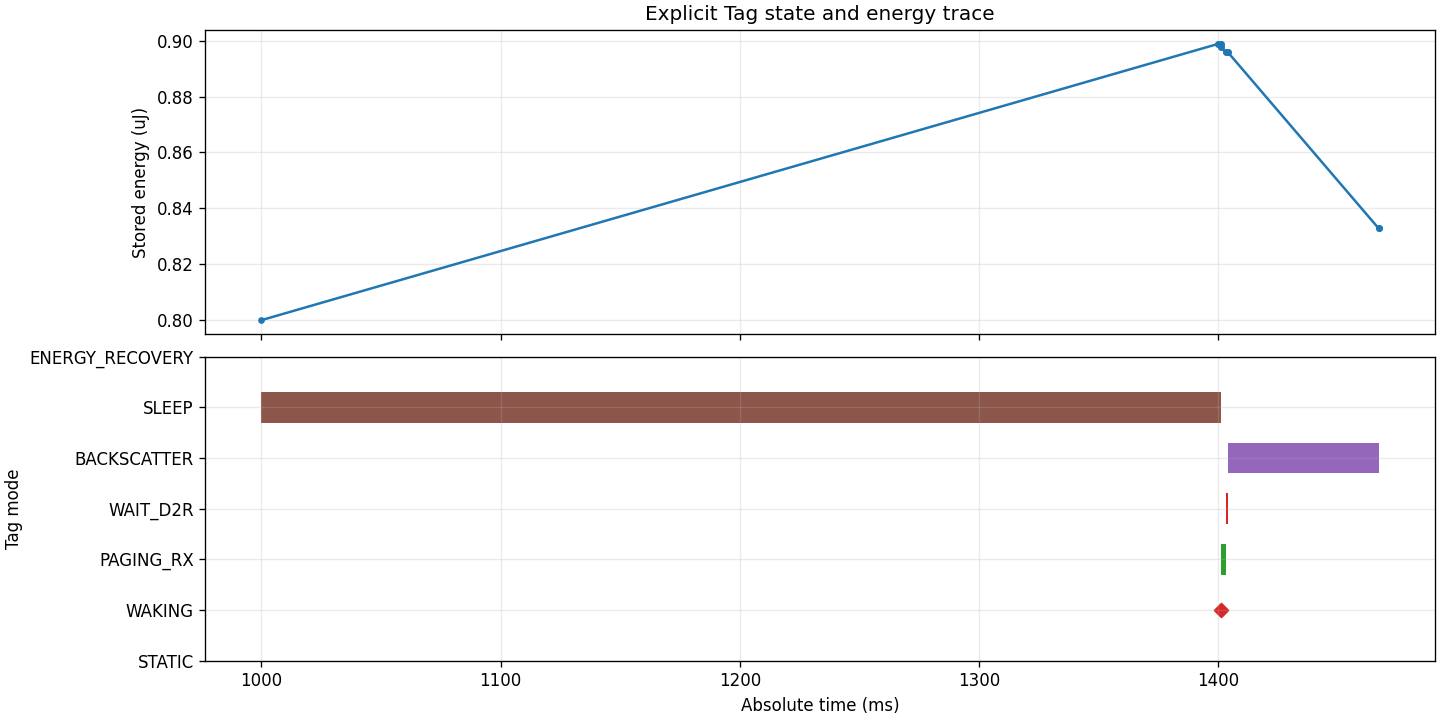

In [18]:
state_times_ms = []
state_energy_uj = []
for row in state_trace_rows:
    state_times_ms.extend([row.start_ns / 1e6, row.end_ns / 1e6])
    state_energy_uj.extend([row.before_j * 1e6, row.after_j * 1e6])

state_figure, state_axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)
state_axes[0].plot(state_times_ms, state_energy_uj, marker='o', markersize=3)
state_axes[0].set(ylabel='Stored energy (uJ)', title='Explicit Tag state and energy trace')
mode_indices = {mode: index for index, mode in enumerate(TagMode)}
for row in state_trace_rows:
    level = mode_indices[row.mode]
    begin_ms = row.start_ns / 1e6
    width_ms = (row.end_ns - row.start_ns) / 1e6
    if width_ms == 0:
        state_axes[1].scatter([begin_ms], [level], marker='D', color='tab:red', s=35)
    else:
        state_axes[1].broken_barh([(begin_ms, width_ms)], (level - 0.3, 0.6), facecolors=f'C{level}')
state_axes[1].set_yticks(list(mode_indices.values()), [mode.value for mode in TagMode])
state_axes[1].set(xlabel='Absolute time (ms)', ylabel='Tag mode')
for axis in state_axes:
    axis.grid(alpha=0.25)
state_plot_buffer = BytesIO()
state_figure.savefig(state_plot_buffer, format='png', dpi=120)
display(Image(data=state_plot_buffer.getvalue()))
plt.close(state_figure)


## 15．耗盡、恢復及重新選擇

第二個 Tag 在空檔起點只剩 0.002 μJ，正常待機於 200 ms 後耗盡。
之後 UL 採能雖讓電量回升，仍維持 ENERGY_RECOVERY，不會自動啟動或回傳。
只有呼叫者在合法決策時點明確選擇一筆可行操作，才進入 WAKING。
背景 trace 的 `mode` 記錄區段起始模式；若中途耗盡，`depletion_after_s` 明列解析切點，快照記錄段末模式。


In [19]:
recovery_example_start = TagSnapshot('Tag-002', 600_000_000, 0.002e-6, TagMode.SLEEP)
depleted_state_trace = advance_tag_interval(recovery_example_start, duration_ns=400_000_000,
                                           phase='GAP')
recovered_state_trace = advance_tag_interval(depleted_state_trace.snapshot, duration_ns=400_000_000,
                                            phase='UE_UL', rf_input_w=rf_input_w)
recovery_switch_trace = advance_tag_interval(recovered_state_trace.snapshot, duration_ns=1_000_000,
                                            phase='RF_SWITCH')
reselected_state_trace = trace_tag_operation(
    recovery_switch_trace.snapshot, tbs_bytes=16,
    paging_ns=example_paging_ns, wait_ns=example_wait_ns,
    window_end_ns=1_600_000_000, deadline_ns=20_000_000_000,
)
show_table([
    {'階段': '空檔耗盡', '段末模式': depleted_state_trace.snapshot.mode.value, '電量 μJ': f'{depleted_state_trace.snapshot.energy_j * 1e6:.9f}'},
    {'階段': 'UL 恢復採能後', '段末模式': recovered_state_trace.snapshot.mode.value, '電量 μJ': f'{recovered_state_trace.snapshot.energy_j * 1e6:.9f}'},
    {'階段': '明確選中並完成操作', '段末模式': reselected_state_trace.snapshot.mode.value, '電量 μJ': f'{reselected_state_trace.snapshot.energy_j * 1e6:.9f}'},
])
display({'耗盡距區段起點 ms': depleted_state_trace.depletion_after_s * 1000,
         '未被重新選中前': recovered_state_trace.snapshot.mode.value})


| 階段 | 段末模式 | 電量 μJ |
| --- | --- | --- |
| 空檔耗盡 | ENERGY_RECOVERY | 0.000000000 |
| UL 恢復採能後 | ENERGY_RECOVERY | 0.102852943 |
| 明確選中並完成操作 | SLEEP | 0.036840943 |

{'耗盡距區段起點 ms': 200.0, '未被重新選中前': 'ENERGY_RECOVERY'}

### 15.1．電量不足必須在啟動前拒絕

下例只剩 0.03 μJ，支付不起上述完整操作。
拒絕是明確的 ValueError；原快照保持原值，也不會先扣掉 1 nJ 才拒絕。


In [20]:
insufficient_example = TagSnapshot('Tag-003', 1_401_000_000, 0.03e-6, TagMode.SLEEP)
try:
    trace_tag_operation(insufficient_example, tbs_bytes=16,
                        paging_ns=example_paging_ns, wait_ns=example_wait_ns,
                        window_end_ns=1_600_000_000, deadline_ns=20_000_000_000)
except ValueError as error:
    display({'結果': '操作被拒絕', '原因': str(error),
             '原電量仍為 μJ': insufficient_example.energy_j * 1e6})
else:
    raise AssertionError('The unaffordable example must be refused')


{'結果': '操作被拒絕',
 '原因': 'stored energy does not cover the complete operation',
 '原電量仍為 μJ': 0.03}

## 16．核對狀態切換與能量成本

這些斷言檢查本次明列案例，不代表已接入完整環境。
再以接收失敗重跑同一操作，檢查狀態時長與扣能沒有被退款。


In [21]:
assert state_operation_trace.snapshot.mode is TagMode.SLEEP
assert state_operation_trace.snapshot.now_ns == 1_467_200_000
assert math.isclose(state_operation_trace.snapshot.energy_j, 0.8328309428383909e-6, rel_tol=1e-12)
assert math.isclose(sum(row.consumed_j for row in state_operation_trace.rows), 66.012e-9, rel_tol=1e-12)
assert state_operation_trace.rows[0].start_ns == state_operation_trace.rows[0].end_ns
assert state_example_start.energy_j == snapshot_energy_j
assert depleted_state_trace.snapshot.mode is TagMode.ENERGY_RECOVERY
assert depleted_state_trace.depletion_after_s == 0.2
assert recovered_state_trace.snapshot.mode is TagMode.ENERGY_RECOVERY
assert math.isclose(reselected_state_trace.snapshot.energy_j, 0.03684094283839096e-6, rel_tol=1e-12)
assert insufficient_example.energy_j == 0.03e-6

failed_state_trace = trace_tag_operation(
    state_switch_trace.snapshot, tbs_bytes=16, paging_ns=example_paging_ns,
    wait_ns=example_wait_ns, window_end_ns=1_600_000_000,
    deadline_ns=20_000_000_000, receive_success=False,
)
assert failed_state_trace.snapshot == state_operation_trace.snapshot
assert failed_state_trace.receive_success is False
state_verification_summary = {
    'states': len(TagMode), 'operation_rows': len(state_operation_trace.rows),
    'blocking_model_decisions': 0, 'status': 'PASS: explicit state trace, not full Engine',
}
display(state_verification_summary)


{'states': 7,
 'operation_rows': 5,
 'blocking_model_decisions': 0,
 'status': 'PASS: explicit state trace, not full Engine'}

## 17．本單元完成到哪裡

本單元已有可執行的充電與 Tag 狀態 trace，包含不可變快照、完整操作能量／時間檢查、拒絕路徑及背景恢復。
尚未實作完整 Tag 狀態引擎的事件佇列與環境接線，也沒有 ServiceManager、FBL 抽樣或 Baseline。操作結果與時序由示範明列。

目前針對本次狀態 trace，待決模型選項為 **0**；狀態、功耗、啟動與恢復規則都已確認。
後續仍有 Baseline、公平性評估與正式實驗設計三組研究工作；實際 CFA 時序／RF 來源 adapter 是後續工程整合輸入。
這些工作不阻擋本次 Notebook 的獨立狀態驗證，也不能由示範的 1 ms 等待值取代。

- [中文設計導讀](../docs/architecture/tag-energy-trace/README.zh-TW.md)
- [狀態設計與選值理由](../docs/architecture/tag-state-design.md)
- [程式／模型追蹤](../docs/architecture/tag-energy-trace/code-trace.md)

核心先留在 Notebook，待您逐段接受後再決定抽離。Baseline 保留待您提供算法。
研究參數尚未完成硬體標定；執行成功不代表實際充電效率、無線可行性或服務完成率已驗證。
